# Preparación de los datos
El primer paso será importar las librerias necesarias, cargar los datos y hacer un proceso de limpieza de los valores nulos. 

In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv('/workspace/dataset.csv')

df.columns = df.columns.str.strip()

key_columns = [
    'BMI', 'GDP', 'Schooling', 'Adult Mortality', 
    'Income composition of resources', 'Life expectancy'
]

df_cleaned = df.dropna(subset=key_columns)

print("Valores nulos restantes en columnas clave:")
print(df_cleaned[key_columns].isnull().sum())

Valores nulos restantes en columnas clave:
BMI                                0
GDP                                0
Schooling                          0
Adult Mortality                    0
Income composition of resources    0
Life expectancy                    0
dtype: int64


# División del dataset
Dividiremos el dataset en tres subconjuntos: entrenamiento, validación y pruebas. 

In [3]:
X = df_cleaned[['BMI', 'GDP', 'Schooling', 'Adult Mortality', 'Income composition of resources']]
y = df_cleaned['Life expectancy']

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=(0.20/0.85), random_state=42)

print(f"Tamaño del set de entrenamiento: {len(X_train)} (65%)")
print(f"Tamaño del set de validación: {len(X_val)} (20%)")
print(f"Tamaño del set de prueba: {len(X_test)} (15%)")

Tamaño del set de entrenamiento: 1597 (65%)
Tamaño del set de validación: 492 (20%)
Tamaño del set de prueba: 369 (15%)


# Normalización de los datos
Para asegurar que todas las variables tengan una escala similar es necesario normalizar algunas características. 

In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Conversión de datos a tensores de PyTorch


In [6]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# Creación de DataLoaders
Vamos a agrupar los datos en batches. De este modo podemos entrenar el modelo eficientemente y en paralelo. 

In [7]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 32
num_workers = 4

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

# Definición del modelo
En este paso vamos a crear la red neuronal de tipo feed-forward con dos capas ocultas y una de salida con una sola neurona. 

In [8]:
class LifeExpectancyNN(nn.Module):
    def __init__(self, input_dim):
        super(LifeExpectancyNN, self).__init__()
        self.hidden1 = nn.Linear(input_dim, 64)
        self.hidden2 = nn.Linear(64, 32)
        self.output = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.relu(self.hidden2(x))
        x = self.output(x) 
        return x

input_dim = X_train_tensor.shape[1]
model = LifeExpectancyNN(input_dim)

# Definir la función de pérdida y el optimizador
Al ser un rproblema de regresión se usa como función de pérdida el MSE. 

Además, vamos a emplear Adam como optimizador. 

In [9]:
criterion = nn.MSELoss()

learning_rate = 0.001
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=0.01)

# Entrenamiento del modelo
Vamos a entrenar el modelo durante 100 épocas y a monitorear el progreso del modelo. 

In [10]:
epochs = 100
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train() 
    running_train_loss = 0.0
    
    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * inputs.size(0)
        
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)
    
    model.eval() 
    running_val_loss = 0.0
    
    with torch.no_grad(): 
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * inputs.size(0)
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Época [{epoch+1}/{epochs}] | Pérdida Entrenamiento: {epoch_train_loss:.4f} | Pérdida Validación: {epoch_val_loss:.4f}")

Época [1/100] | Pérdida Entrenamiento: 4747.3489 | Pérdida Validación: 276.5702
Época [10/100] | Pérdida Entrenamiento: 100.9356 | Pérdida Validación: 5.6568
Época [20/100] | Pérdida Entrenamiento: 28.4517 | Pérdida Validación: 1.3975
Época [30/100] | Pérdida Entrenamiento: 17.0418 | Pérdida Validación: 0.9543
Época [40/100] | Pérdida Entrenamiento: 14.3090 | Pérdida Validación: 0.7493
Época [50/100] | Pérdida Entrenamiento: 12.9999 | Pérdida Validación: 0.3500
Época [60/100] | Pérdida Entrenamiento: 10.3284 | Pérdida Validación: 0.4589
Época [70/100] | Pérdida Entrenamiento: 8.6222 | Pérdida Validación: 0.3147
Época [80/100] | Pérdida Entrenamiento: 8.1140 | Pérdida Validación: 0.4630
Época [90/100] | Pérdida Entrenamiento: 7.7612 | Pérdida Validación: 0.4981
Época [100/100] | Pérdida Entrenamiento: 7.5626 | Pérdida Validación: 0.4947


# Graficar la curva de pérdida
A través de las gráficas vamos a ver como el modelo está aprendiendo y si hay sobreajuste o subajuste. 

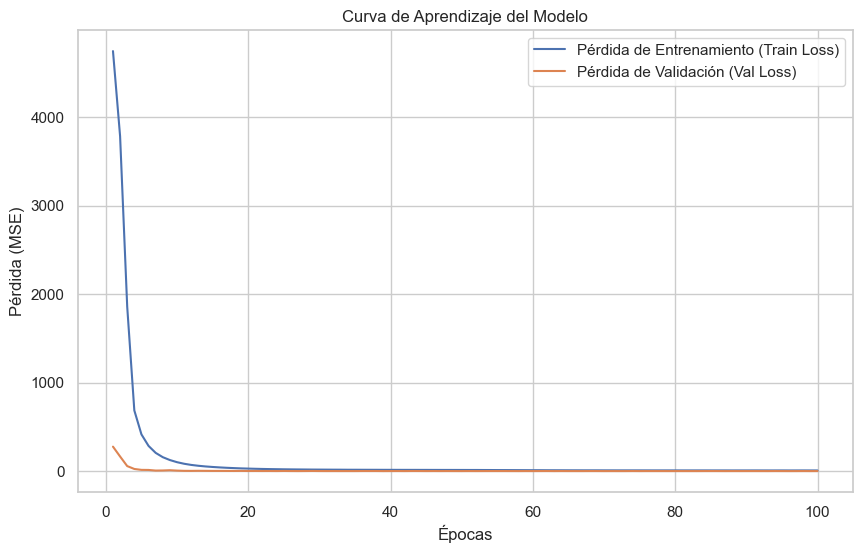

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Pérdida de Entrenamiento (Train Loss)')
plt.plot(range(1, epochs + 1), val_losses, label='Pérdida de Validación (Val Loss)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (MSE)')
plt.title('Curva de Aprendizaje del Modelo')
plt.legend()
plt.show()

# Evaluar el modelo
A través del conjunto de prueba vamos a calcular la pérdida final. 

In [12]:
model.eval()
test_loss = 0.0

with torch.no_grad():
    for inputs, targets in test_loader:
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        test_loss += loss.item() * inputs.size(0)

final_test_loss = test_loss / len(test_loader.dataset)

print(f"--- Evaluación Final en el Conjunto de Prueba ---")
print(f"Pérdida (MSE) en Test: {final_test_loss:.4f}")

--- Evaluación Final en el Conjunto de Prueba ---
Pérdida (MSE) en Test: 9.6293
